![Banner](../images/09_11_banner_rs_foundation_models.png)

# From a GeoTIFF to an Embedding Map

Every foundation model was trained on inputs of one particular form: certain bands in a certain
order, values in certain units, a certain normalization and chip size. Feed it something else and
it still returns embeddings, only worse ones, and nothing warns you. This notebook takes a
Sentinel-2 scene of the Iowa Corn Belt through the whole path from raster to embedding map with
`geolattice.rsense.foundation_models`: reading the input contract of a model, preparing bands, chipping,
embedding with four different models, measuring what a wrong normalization costs, timing CPU and
GPU, and saving the result so it can be reused without the model.

## Overview

### The input contract of a model

A pretrained encoder learned its weights from data prepared in one way. Five properties of that
preparation define its **input contract**:

| Property | Example | What goes wrong if it differs |
|---|---|---|
| Bands and their order | Prithvi: blue, green, red, narrow NIR, SWIR 1, SWIR 2 | the first layer applies "red" weights to the NIR band |
| Units | digital numbers (reflectance x 10,000), reflectance 0 to 1, dB for SAR | values are 10,000 times too small or large |
| Normalization | per-band mean and standard deviation of the pretraining data | features drift away from the range the model has seen |
| Chip size and resolution | 224 pixels at 30 m (Prithvi), 256 at 10 m (Satlas) | objects appear at a scale the model never saw |
| Time steps | 1 to 4 frames (Prithvi-EO-2.0) | wrong tensor shape, or frames read as bands |

Wavelength-aware models (DOFA, Copernicus-FM, Panopticon) relax the first property: they build
their input layer from the band wavelengths, so any band set works, but units and normalization
still matter.

### Pooled and patch embeddings

`embed_raster` cuts a raster into chips and returns one vector per chip (**pooled**), or with
`dense=True` the grid of patch vectors inside every chip. A chip is the unit the model sees at
once: a 224 pixel chip of 20 m Sentinel-2 covers 4.5 km, so its pooled embedding describes a
landscape, while 32 pixel chips resized to 224 describe single fields. Resizing changes the
apparent ground resolution, another departure from the contract that this notebook makes on
purpose and measures.

### Why it fails silently

A neural network has no notion of units. A chip in reflectance (0 to 0.5) given to a model that
expects digital numbers (0 to 5,000) produces activations near zero, a nearly constant embedding
and a probe that barely beats guessing, yet no error is raised. The only defence is to check the
contract (`fm.input_spec`) and to measure, as below.

## Embedding Rasters with GeoLattice

| Function | Purpose |
|---|---|
| `fm.input_spec(name)` | the input contract: bands, units, statistics, chip size |
| `fm.prepare(name, da)` | reorder and fill bands, convert units, normalize |
| `fm.band_wavelengths(bands)` | band centre wavelengths for wavelength-aware models |
| `fm.chip_raster(da, chip_size, stride)` | cut a raster into chips with chip centre coordinates |
| `fm.load_model(name)` | a `FoundationEncoder` with `encode`, `embed`, `embed_raster`, `dense_features` |
| `fm.embedding_rgb`, `fm.embeddings_to_frame` | view and tabulate embedding maps |

### Learning objectives

1. Read the input contract of a model and prepare a raster to match it.
2. Know the parts of a `FoundationEncoder` and the difference between pooled and patch embeddings.
3. Cut a raster into chips and keep their georeferencing.
4. Embed one scene with four models and compare the embedding maps.
5. Measure the cost of a wrong normalization with a linear probe.
6. Time embedding on the CPU and the GPU, and save embeddings with their provenance.

### Data

| Dataset | Content |
|---|---|
| Corn Belt Sentinel-2 cube | Iowa, 30 x 29 km, 10 bands at 20 m, 26 August 2025 (from the 34-date cube of chapter 08_09) |
| Cropland Data Layer 2025 | USDA CDL on the same 20 m grid, grouped into six classes |

### Contents

- Setup
- The input contract
- Anatomy of a FoundationEncoder
- Preparing a raster for a model
- Chips and their labels
- Four models, four embedding maps
- What a wrong normalization costs
- CPU and GPU
- Saving embeddings with their provenance
- From the image classification loaders to fm
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

CUBE = IC / "Corn_belt" / "cache_20m"  # Corn Belt cubes on the 20 m grid
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # CDL groups 0 to 5
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]  # one colour per class

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


The scene is one date of the Corn Belt cube built in chapter 08_09: ten Sentinel-2 L2A bands
resampled to 20 m, in surface reflectance (0 to 1), clouds set to NaN. The CDL of the same year
is on the same grid.

{'band': 10, 'y': 1456, 'x': 1516} | bands: [np.str_('blue'), np.str_('green'), np.str_('red'), np.str_('rededge1'), np.str_('rededge2'), np.str_('rededge3'), np.str_('nir'), np.str_('nir08'), np.str_('swir16'), np.str_('swir22')]
cloud or no data: 0.22%


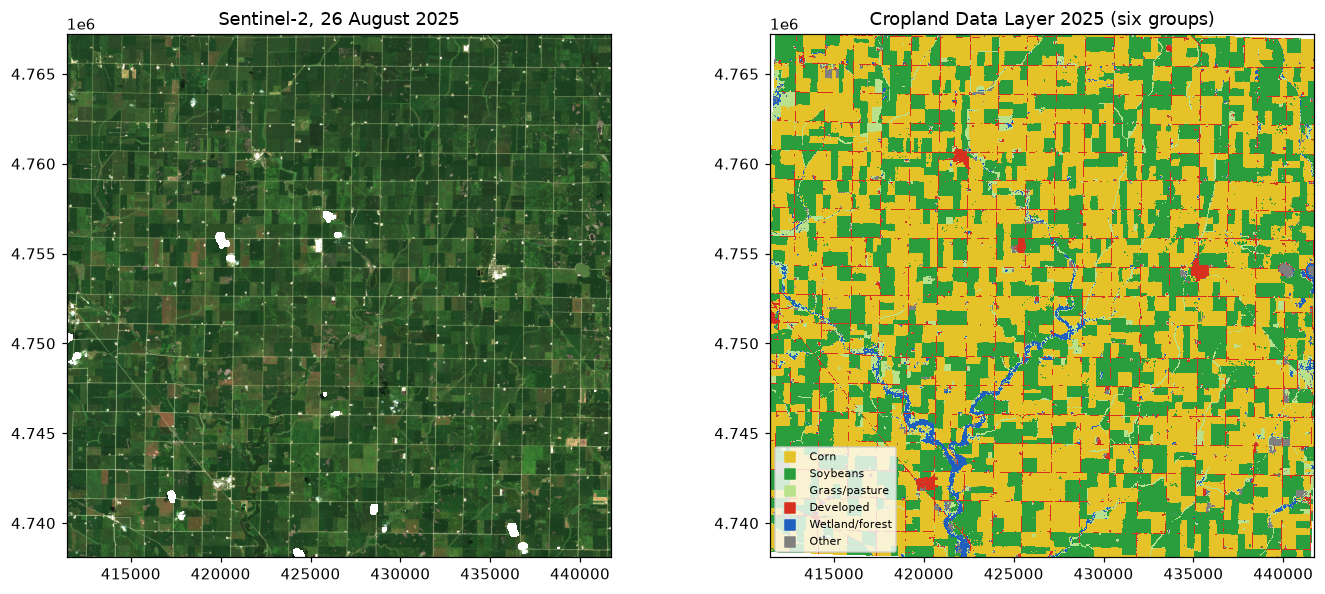

In [2]:
s2 = xr.open_dataarray(CUBE / "s2_20m.nc").sel(time="2025-08-26").load()  # (band, y, x) reflectance
s2 = s2.drop_vars("time").rio.write_crs("EPSG:32615")  # UTM zone 15N
cdl = xr.open_dataset(CUBE / "labels_20m.nc")["cdl"].sel(year=2025).load()  # CDL classes 0 to 5, -1 none
print(dict(s2.sizes), "| bands:", list(s2.band.values))  # size and band names
print("cloud or no data:", f"{float(s2.isnull().any('band').mean()):.2%}")  # missing pixels

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))  # two panels
ext = [float(s2.x.min()), float(s2.x.max()), float(s2.y.min()), float(s2.y.max())]  # map extent
rgb = np.clip(s2.sel(band=["red", "green", "blue"]).transpose("y", "x", "band").values / 0.15, 0, 1)  # true colour
ax[0].imshow(rgb, extent=ext); ax[0].set_title("Sentinel-2, 26 August 2025")  # image
from matplotlib.colors import ListedColormap  # discrete colours
ax[1].imshow(np.ma.masked_less(cdl.values, 0), cmap=ListedColormap(COLORS), vmin=-0.5, vmax=5.5,
             extent=ext, interpolation="nearest")  # CDL classes
ax[1].set_title("Cropland Data Layer 2025 (six groups)")  # title
for c, col in zip(CLASSES, COLORS):  # legend
    ax[1].scatter([], [], color=col, marker="s", label=c)  # empty handle
ax[1].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()  # draw

## The input contract

`fm.input_spec` returns the contract recorded for a model: the bands in order (GeoLattice names), the
units the statistics refer to, the mean and standard deviation, and the chip size. The values come
from the TorchGeo weight transforms, the TerraTorch pretraining constants and the model cards.

In [3]:
names = ["prithvi-eo-2.0-300m", "ssl4eo-s12-resnet18-moco", "satlas-swint-s2-ms", "scale-mae",
         "terramind-v1-base", "dofa-base", "panopticon", "ssl4eo-s1-resnet50-moco"]  # models to compare
rows = []  # one row per model
for n in names:  # every model
    sp = fm.input_spec(n)  # its contract
    rows.append({"model": n, "bands": "any (wavelength-aware)" if sp["bands"] is None else ", ".join(sp["bands"]),
                 "units": sp["units"], "statistics": "per-band standardization" if sp["mean"] is None
                 else f"mean {sp['mean'][0]:g}.., std {sp['std'][0]:g}..", "chip": sp["img_size"]})  # summary
pd.DataFrame(rows).set_index("model")  # the contracts side by side

,bands,units,statistics,chip
model,,,,
prithvi-eo-2.0-300m,"blue, green, red, nir08, swir16, swir22",dn,"mean 1087.., std 2248..",224
ssl4eo-s12-resnet18-moco,"coastal, blue, green, red, rededge1, rededge2,...",dn,"mean 0.., std 10000..",224
satlas-swint-s2-ms,"red, green, blue, rededge1, rededge2, rededge3...",dn,"mean 0.., std 3000..",256
scale-mae,"red, green, blue",unit,"mean 0.485.., std 0.229..",224
terramind-v1-base,"coastal, blue, green, red, rededge1, rededge2,...",dn,"mean 1390.46.., std 2106.76..",224
dofa-base,any (wavelength-aware),any,per-band standardization,224
panopticon,any (wavelength-aware),any,per-band standardization,224
ssl4eo-s1-resnet50-moco,"vv, vh",db,"mean -12.59.., std 5.26..",224


Three patterns stand out. Prithvi and TerraMind standardize digital numbers with the statistics of
their pretraining archives. SSL4EO and Satlas only divide by a constant (Satlas takes red, green
and blue from Sentinel-2's 8-bit true colour product, which `prepare` approximates by dividing by
3,000). DOFA and Panopticon accept any bands and have no fixed statistics, so each band is
standardized over the scene.

## Anatomy of a FoundationEncoder

`fm.load_model` builds the network, downloads the weights on first use and wraps both in a
`FoundationEncoder`. The SSL4EO ResNet-18 is small and quick, so it is a good first example.

In [4]:
enc = fm.load_model("ssl4eo-s12-resnet18-moco", device=DEVICE)  # SSL4EO-S12 ResNet-18, MoCo weights
print(enc)  # name, loader, embedding size, device
print("catalog entry:", enc.spec.architecture, "|", enc.spec.inputs)  # the catalog record it came from
print("network:", type(enc.model).__name__, "|", f"{sum(p.numel() for p in enc.model.parameters()) / 1e6:.1f} M parameters")  # the torch module
x = torch.randn(2, 13, 224, 224)  # two random 13-band chips
print("forward_features:", tuple(enc.forward_features(x).shape))  # raw output: a feature map
print("encode:", tuple(enc.encode(x).shape))  # pooled: one vector per chip

FoundationEncoder('ssl4eo-s12-resnet18-moco', loader='torchgeo', embed_dim=512, device=cuda)
catalog entry: ResNet-18, MoCo-v2 | Sentinel-2 L1C 13 bands, reflectance / 10000
network: ResNet | 11.2 M parameters
forward_features: (2, 512, 7, 7)
encode: (2, 512)


`forward_features` returns what the network produces: for a ResNet a 512 x 7 x 7 feature map (the
224 pixel chip downsampled 32 times). `encode` pools it to one 512 value vector per chip, and
`embed` does the same in batches and returns NumPy. A vision transformer returns tokens instead,
and pooling can take the class token or the mean of the patch tokens.

In [5]:
vit = fm.load_model("ssl4eo-s12-vits16-dino", device=DEVICE)  # SSL4EO ViT-Small, DINO weights
tok = vit.forward_features(x)  # (chips, 1 + 196 tokens, 384)
cls_vec, mean_vec = vit.encode(x, pool="cls"), vit.encode(x, pool="mean")  # two pooling choices
print("tokens:", tuple(tok.shape), "| dense grid:", vit.dense_features(x).shape)  # tokens and patch grid
print("cosine(CLS, mean of patches):",
      torch.nn.functional.cosine_similarity(cls_vec, mean_vec).cpu().numpy().round(3))  # how different they are

tokens: (2, 197, 384) | dense grid: (2, 384, 14, 14)
cosine(CLS, mean of patches): [0.107 0.074]


The 197 tokens are one class token plus a 14 x 14 grid of 16 pixel patches; `dense_features`
drops the class token and reshapes the rest into that grid. The CLS vector and the mean of the
patch tokens are different summaries of the same chip, which is why the pooling choice must stay
fixed within an analysis.

## Preparing a raster for a model

`fm.prepare` applies the contract to a raster. For the SSL4EO model the Corn Belt stack lacks
three of the thirteen bands (coastal aerosol, water vapour and cirrus); `prepare` fills each from
the band nearest in wavelength and records what it filled. For Prithvi it picks six bands, converts
reflectance to digital numbers and standardizes with the HLS statistics.

In [6]:
for n in ["ssl4eo-s12-resnet18-moco", "prithvi-eo-2.0-300m", "satlas-swint-s2-ms", "dofa-base"]:  # four contracts
    p = fm.prepare(n, s2)  # bands, units and normalization for model n
    print(f"{n:26s} bands {p.sizes['band']:2d} | filled: {p.attrs['filled_bands'] or '-':28s} | "
          f"mean {float(p.mean()):6.2f}, std {float(p.std()):5.2f}")  # what prepare did
print("wavelengths (nm) used by DOFA:", fm.band_wavelengths(list(s2.band.values)))  # DOFA reads these

ssl4eo-s12-resnet18-moco   bands 13 | filled: coastal,watervapor,cirrus    | mean   0.20, std  0.17


prithvi-eo-2.0-300m        bands  6 | filled: -                            | mean  -0.17, std  0.53


satlas-swint-s2-ms         bands  9 | filled: -                            | mean   0.24, std  0.17


dofa-base                  bands 10 | filled: -                            | mean  -0.00, std  1.00
wavelengths (nm) used by DOFA: [490.0, 560.0, 665.0, 705.0, 740.0, 783.0, 842.0, 865.0, 1610.0, 2190.0]


After preparation Prithvi's values have a mean near zero and a standard deviation near one, as the
pretraining data had; the SSL4EO input is reflectance, as SSL4EO expects. Filling missing bands
from neighbours is a compromise: the coastal band (443 nm) copied from blue (490 nm) is close, the
cirrus band (1375 nm) copied from SWIR 1 (1610 nm) is not, since real cirrus reflectance is near
zero over clear land. The probe below shows how much such compromises cost.

## Chips and their labels

`fm.chip_raster` cuts the scene into square chips and returns the coordinates of their centres.
Here the chips are 32 pixels (640 m), about one field, so each chip can carry one crop label: the
majority CDL class, kept when it covers at least 60 % of the chip. The scene edges are padded by
reflection so every pixel falls in a chip.

In [7]:
CHIP = 32  # chip size in 20 m pixels (640 m)
chips, ys, xs = fm.chip_raster(s2, chip_size=CHIP)  # (n, band, 32, 32) and chip centres
print("chips:", chips.shape, f"on a {len(ys)} x {len(xs)} grid")  # count and layout


def chip_labels(lab, chip):  # majority class and its share in every chip (row-major order)
    a = lab.values  # class codes, -1 = none
    ny, nx = -(-a.shape[0] // chip), -(-a.shape[1] // chip)  # chips per column and row
    pad = np.full((ny * chip, nx * chip), -1, a.dtype); pad[:a.shape[0], :a.shape[1]] = a  # pad with "none"
    blocks = pad.reshape(ny, chip, nx, chip).transpose(0, 2, 1, 3).reshape(ny * nx, -1)  # pixels per chip
    counts = np.stack([(blocks == k).sum(1) for k in range(len(CLASSES))], 1)  # pixels per class
    return counts.argmax(1), counts.max(1) / blocks.shape[1]  # majority class and its share


major, purity = chip_labels(cdl, CHIP)  # one label per chip
ok = purity >= 0.6  # chips dominated by one class
gy, gx = np.divmod(np.arange(len(major)), len(xs))  # chip row and column
block = (gy // 9) * 10 + gx // 9  # 9 x 9 chip blocks (5.8 km) for spatial cross-validation
print(ok.sum(), "labelled chips in", len(np.unique(block[ok])), "spatial blocks")  # usable samples
pd.Series(major[ok]).map(dict(enumerate(CLASSES))).value_counts()  # chips per class

chips: (2208, 10, 32, 32) on a 46 x 48 grid
1458 labelled chips in 30 spatial blocks


Corn              940
Soybeans          509
Grass/pasture       5
Developed           3
Wetland/forest      1
Name: count, dtype: int64

Corn and soybeans dominate, as they do in Iowa; developed land and wetland/forest chips are rare,
because 640 m chips seldom contain 60 % of either. The blocks group neighbouring chips, so a probe
trained in one block is tested in other blocks, not on the field next door.

## Four models, four embedding maps

`embed_raster(norm="model")` prepares the scene with the model's contract, chips it and resizes
each 32 pixel chip to the model's input size. The four models differ in architecture and
pretraining data: an SSL4EO ResNet-18, a Satlas Swin-T, DOFA and Panopticon.

In [8]:
MODELS = ["ssl4eo-s12-resnet18-moco", "satlas-swint-s2-ms", "dofa-base", "panopticon"]  # models to compare
emb, secs = {}, {}  # embedding maps and run times
for n in MODELS:  # every model
    e = fm.load_model(n, device=DEVICE)  # load (downloads once)
    t0 = time.perf_counter()  # start the clock
    emb[n] = e.embed_raster(s2, chip_size=CHIP, norm="model", batch_size=64)  # (D, 46, 48) map
    secs[n] = time.perf_counter() - t0  # seconds for the scene
    del e; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free the GPU
pd.DataFrame({"embedding size": {n: emb[n].sizes["embedding"] for n in MODELS},
              "seconds for the scene": pd.Series(secs).round(1)})  # sizes and run times

,embedding size,seconds for the scene
ssl4eo-s12-resnet18-moco,512,2.3
satlas-swint-s2-ms,768,9.3
dofa-base,768,15.5
panopticon,768,41.5


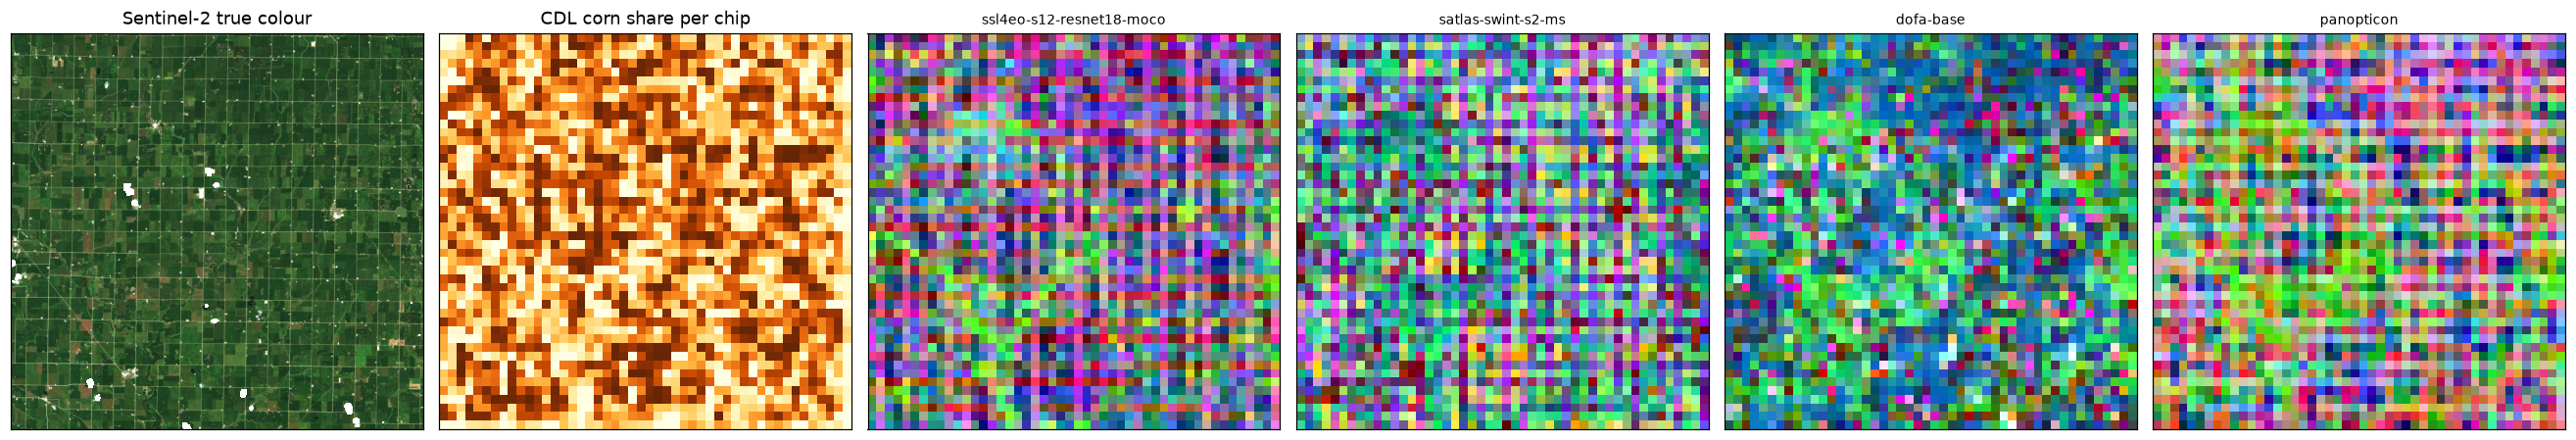

In [9]:
pad = np.full((len(ys) * CHIP, len(xs) * CHIP), -1); pad[:cdl.shape[0], :cdl.shape[1]] = cdl.values  # padded CDL
corn = (pad.reshape(len(ys), CHIP, len(xs), CHIP) == 0).mean((1, 3))  # share of corn in every chip
fig, ax = plt.subplots(1, 6, figsize=(24, 4.4))  # six panels
ax[0].imshow(rgb, extent=ext); ax[0].set_title("Sentinel-2 true colour")  # the scene
ax[1].imshow(corn, cmap="YlOrBr", extent=ext, interpolation="nearest"); ax[1].set_title("CDL corn share per chip")  # reference
for a, n in zip(ax[2:], MODELS):  # every model
    a.imshow(fm.embedding_rgb(emb[n]).transpose("y", "x", "band"), extent=ext, interpolation="nearest")  # PCA colours
    a.set_title(n, fontsize=9)  # model name
for a in ax:  # all panels
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Each model panel shows the first three principal components of its embeddings as colours, one
square per 640 m chip. The maps look speckled, and so does the corn share: in this landscape of
square-mile sections every chip holds a different mix of corn and soybean fields, so neighbouring
chips differ more than distant regions do. The models still disagree with one another. DOFA's
colours vary most smoothly across the scene, while the ResNet, Swin and Panopticon maps change
more from chip to chip, a sign that they respond to different contrasts within each chip. A visual
impression is not a measure, so a probe follows.

`fm.embeddings_to_frame` flattens a map to a table, one row per chip with its coordinates, ready to
join with labels or to export.

In [10]:
tab = fm.embeddings_to_frame(emb["dofa-base"], dropna=False)  # one row per chip
tab["class"] = pd.Series(major).map(dict(enumerate(CLASSES))).where(ok)  # CDL class of usable chips
tab.iloc[:5, list(range(5)) + [-1]]  # first columns

,y,x,e000,e001,e002,class
0,4766900.0,411740.0,-0.094661,-0.805666,-0.328185,NaN
1,4766900.0,412380.0,-0.065035,-0.662149,-0.451274,Soybeans
2,4766900.0,413020.0,-0.093712,-0.792667,-0.411797,Soybeans
3,4766900.0,413660.0,0.067593,-0.535428,-0.275365,Corn
4,4766900.0,414300.0,0.213348,-0.630041,-0.208639,Corn


A linear probe with spatial-block cross-validation measures how much crop information each map
holds. Only corn and soybeans have at least 20 pure chips, so the probe separates those two; the
rare classes would make the macro F1 score meaningless. The baseline is the mean reflectance of
the ten bands in each chip.

In [11]:
ok &= np.isin(major, np.flatnonzero(np.bincount(major[ok], minlength=len(CLASSES)) >= 20))  # classes with 20+ chips
y_ok, g_ok = major[ok], block[ok]  # labels and blocks of usable chips
print(ok.sum(), "chips:", pd.Series(y_ok).map(dict(enumerate(CLASSES))).value_counts().to_dict())  # what the probe sees
flat = lambda m: m.values.reshape(m.sizes["embedding"], -1).T  # (chips, D) in chip order
bandmean = np.nan_to_num(chips.mean((2, 3)))  # baseline: mean reflectance per band and chip
res = {"band means (baseline)": fm.linear_probe(bandmean[ok], y_ok, groups=g_ok)["mean"]}  # baseline probe
for n in MODELS:  # every model
    res[n] = fm.linear_probe(flat(emb[n])[ok], y_ok, groups=g_ok)["mean"]  # spatial 5-fold probe
probe = pd.DataFrame(res).T.round(3)  # accuracy and macro F1 per input
probe

1449 chips: {'Corn': 940, 'Soybeans': 509}


,accuracy,f1_macro
band means (baseline),0.988,0.986
ssl4eo-s12-resnet18-moco,0.966,0.963
satlas-swint-s2-ms,0.987,0.986
dofa-base,0.998,0.998
panopticon,0.994,0.993


In late August corn and soybeans differ so clearly in their spectra that the ten band means
already classify almost every chip correctly, so there is little room for any encoder to add
information. DOFA and Panopticon reach slightly higher scores than the baseline, Satlas matches
it and the SSL4EO ResNet-18 falls below it, with three of its thirteen input bands filled from
neighbours. That is a lesson in itself: when a simple spectral baseline nearly saturates, a
foundation model brings cost, not accuracy. Notebook 09_11_04 moves to a harder setting (patch
embeddings, an early-season date and fewer labels), where the differences between models are
larger.

## What a wrong normalization costs

The same SSL4EO model is run three ways: with its contract (reflectance, the SSL4EO scaling), with
reflectance mistaken for digital numbers (values 10,000 times too small), and with per-scene
standardization instead of the model's statistics. The cosine similarity to the correct embeddings
and the probe accuracy show the cost.

In [12]:
ssl = fm.load_model("ssl4eo-s12-resnet18-moco", device=DEVICE)  # the SSL4EO ResNet-18 again
variants = {  # three ways of preparing the same scene
    "contract (reflectance)": fm.prepare("ssl4eo-s12-resnet18-moco", s2),  # correct
    "reflectance read as DN": fm.prepare("ssl4eo-s12-resnet18-moco", s2, units="dn"),  # 10,000 times too small
}
variants["per-scene standardization"] = fm.prepare("ssl4eo-s12-resnet18-moco", s2).pipe(
    lambda p: (p - p.mean(("y", "x"))) / p.std(("y", "x")))  # same 13 bands, standardized instead of scaled
E = {k: flat(ssl.embed_raster(v, chip_size=CHIP, norm={"method": "none"}, batch_size=64))
     for k, v in variants.items()}  # embeddings for each variant
ref = E["contract (reflectance)"]  # the correct embeddings
cos = lambda a, b: (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12)  # row cosine
pd.DataFrame({k: {"median cosine to contract": float(np.median(cos(v, ref))),
                  "probe accuracy": fm.linear_probe(v[ok], y_ok, groups=g_ok)["mean"]["accuracy"]}
              for k, v in E.items()}).T.round(3)  # cost of each mistake

,median cosine to contract,probe accuracy
contract (reflectance),1.000,0.966
reflectance read as DN,0.230,0.959
per-scene standardization,0.248,0.959


The table quantifies two different kinds of damage. Embeddings computed from inputs on the wrong
scale point in a different direction from the correct ones (a low cosine similarity), so they
cannot be mixed with embeddings computed correctly elsewhere, for example a stored index. The
probe accuracy can still look reasonable, because a linear probe re-learns whatever structure is
left, and that is exactly what makes the error silent. Per-scene standardization changes the
values without changing their order within each band, so it often hurts less, but the embeddings
of two scenes standardized separately are no longer comparable.

## CPU and GPU

Embedding is inference only, so a CPU works; a GPU is faster for large models and large areas.
The same 512 chips are embedded on each device.

In [13]:
rows = []  # timings
for n in ["ssl4eo-s12-resnet18-moco", "dofa-base"]:  # a small and a medium model
    for dev in (["cpu", "cuda"] if DEVICE == "cuda" else ["cpu"]):  # available devices
        e = fm.load_model(n, device=dev, bands=list(s2.band.values))  # model on that device
        x = fm.prepare(n, s2).isel(y=slice(0, 32 * 16), x=slice(0, 32 * 32))  # a prepared 512-chip block
        c, _, _ = fm.chip_raster(x, chip_size=CHIP)  # its chips
        c = torch.nn.functional.interpolate(torch.as_tensor(c), size=e.img_size, mode="bilinear").numpy()  # model size
        e.embed(c[:32], batch_size=32)  # warm-up (kernels, memory)
        t0 = time.perf_counter(); e.embed(c, batch_size=64)  # timed run
        if dev == "cuda":  # wait for the GPU to finish
            torch.cuda.synchronize()  # synchronize
        rows.append({"model": n, "device": dev, "chips": len(c), "seconds": time.perf_counter() - t0})  # record
        del e  # free memory
t = pd.DataFrame(rows)  # timing table
t["chips per second"] = (t["chips"] / t["seconds"]).round(1)  # throughput
t.round(2)

,model,device,chips,seconds,chips per second
0,ssl4eo-s12-resnet18-moco,cpu,512,6.66,76.8
1,ssl4eo-s12-resnet18-moco,cuda,512,0.34,1524.9
2,dofa-base,cpu,512,49.71,10.3
3,dofa-base,cuda,512,3.96,129.4


On this machine the GPU embeds the chips many times faster than the CPU, and the gap grows with
model size. For a single scene either device is fine; for a country or a time series the GPU, or
a precomputed product such as AlphaEarth (notebook 09_11_07), becomes the practical choice.

## Saving embeddings with their provenance

An embedding map is only reusable if it records how it was made: the model, its weights, the chip
size and the normalization. `embed_raster` writes these as attributes; the map is saved to NetCDF
and read back without loading any model.

In [14]:
m = emb["dofa-base"].copy()  # the DOFA embedding map
m.attrs.update(weights=fm.model_info("dofa-base")["weights"], source="Sentinel-2 L2A 2025-08-26, 20 m",
               crs=str(s2.rio.crs))  # add provenance
path = OUT / "cornbelt_2025-08-26_dofa_chip32.nc"  # file name records the essentials
m.drop_vars("spatial_ref", errors="ignore").to_netcdf(path)  # write
back = xr.open_dataarray(path)  # read back, no model needed
print(path, f"{path.stat().st_size / 2**20:.1f} MB")  # file and size
{k: back.attrs[k] for k in ("model", "chip_size", "stride", "dense", "normalization", "weights", "source")}  # provenance

outputs/cornbelt_2025-08-26_dofa_chip32.nc 6.5 MB


{'model': 'dofa-base',
 'chip_size': np.int64(32),
 'stride': np.int64(32),
 'dense': np.int64(0),
 'normalization': "{'method': 'none'}",
 'weights': 'torchgeo DOFABase16_Weights.DOFA_MAE',
 'source': 'Sentinel-2 L2A 2025-08-26, 20 m'}

## From the image classification loaders to fm

Notebook 09_11_02 uses the older loaders in `geolattice.rsense.classify.image_classification` (`ic`).
They remain available; the table maps them to the `fm` interface used from here on.

| `image_classification` (09_11_02) | `foundation_models` (this chapter) |
|---|---|
| `ic.foundation_model_info()` | `fm.list_models()`, `fm.model_info(name)` |
| `ic.load_foundation_encoder("dofa")` | `fm.load_model("dofa-base", bands=...)` |
| `ic.load_foundation_encoder("prithvi")` | `fm.load_model("prithvi-eo-2.0-300m")` |
| `ic.load_rs_backbone("ssl4eo_s2_resnet18_moco")` | `fm.load_model("ssl4eo-s12-resnet18-moco")` |
| `ic.load_rs_clip("remoteclip-vit-b-32")` | `fm.load_model("remoteclip-vit-b-32")` |
| `ic.zero_shot_classify(...)` | `fm.zero_shot_classify(...)` |
| `ic.embedding_search(...)` | `fm.embedding_search(...)` |
| `ic.terratorch_config(...)` | `fm.terratorch_config(...)` |
| manual band selection and scaling | `fm.prepare(name, da)`, `embed_raster(norm="model")` |

## Summary and exercises

### Summary

- Every model has an input contract: bands and order, units, normalization, chip size and time
  steps. `fm.input_spec` records it and `fm.prepare` applies it, filling missing bands from the
  nearest wavelength and saying which ones it filled.
- A `FoundationEncoder` gives raw outputs (`forward_features`), pooled vectors (`encode`, `embed`),
  patch grids (`dense_features`) and georeferenced maps (`embed_raster`).
- `chip_raster` cuts a raster into chips with their centre coordinates; labels per chip come from the
  majority class and its share.
- Different models produce different embedding maps of the same scene, and a spatial linear probe
  measures how much task information each holds compared with a simple band-mean baseline.
- Wrong units change the direction of the embeddings and may still give a plausible probe score, so
  the error is silent; per-scene standardization makes embeddings of different scenes incomparable.
- A GPU speeds embedding up substantially; saving embeddings with their provenance makes them
  reusable without the model.

### Exercises

1. Run `fm.prepare("terramind-v1-base", s2)` and list the filled bands. Which one is the worst
   substitute, and why?
2. Repeat the four-model probe with 16 pixel chips (320 m). Which classes gain, which lose?
3. Use `embed_raster(..., dense=True)` with the SSL4EO ViT on a 224 pixel chip and plot the 14 x 14
   patch map next to the CDL.
4. Add a fourth normalization variant to the experiment: digital numbers read as reflectance
   (values 10,000 times too large). What happens to the cosine similarity?
5. Save the SSL4EO embedding map with its provenance and write a function that refuses to compare two
   maps whose `model` or `normalization` attributes differ.

### References

- Bastani, F. et al. (2023). SatlasPretrain: a large-scale dataset for remote sensing image understanding. ICCV.
- Szwarcman, D. et al. (2024). Prithvi-EO-2.0: a versatile multi-temporal foundation model for Earth observation applications. arXiv:2412.02732.
- Waldmann, L. et al. (2025). Panopticon: advancing any-sensor foundation models for Earth observation. arXiv:2503.10845.
- Wang, Y. et al. (2023). SSL4EO-S12. IEEE Geoscience and Remote Sensing Magazine.
- Xiong, Z. et al. (2024). DOFA. arXiv:2403.15356.